# STEP 2.5 | 미추홀구 I-MOD 군집 분리도 개선 실험

**대상:** 2026년 4~6월(6월 11일 의도적 제외), 정류장명 기반 정류장군 286개. 공간좌표 매칭 여부로 행을 제외하지 않습니다.

**검증 내용:** 중복 변수 제거 전후 → `StandardScaler`/`RobustScaler` → 수요·공급 규모 로그 변환 → PCA(시각화와 90% 설명분산 축소) → K-Means/GMM → 실루엣·군집 크기·Davies–Bouldin·Calinski–Harabasz → 초기값/재표본 안정성 → 군집별 원 단위 중앙값.

> **주의**: 실루엣을 최대화하는 모델이 반드시 I-MOD 후보 선정에 가장 적합한 것은 아닙니다. 이번 결과는 '정류장 유형' 분류를 평가하는 것이며 실제 대기시간이나 수송 부족의 직접 증거는 아닙니다.

**입력은 파일 하나만:** `03_features_expanded_286.csv` (STEP 1 분석 결과). 노선 수 미확정 2개는 중앙값으로 대체하고 원본 결측 플래그를 보존합니다. 로그는 비음수 규모 지표에만 `log1p` 적용합니다.

In [1]:
# Colab 업로드: 이름에 (1), (2)가 붙어도 작동
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score, calinski_harabasz_score
import warnings, zipfile, os
warnings.filterwarnings('ignore', category=FutureWarning)
INPUT_MARKER='features_expanded_286'
files_here=list(Path('.').glob('*.csv'))
candidates=[p for p in files_here if INPUT_MARKER in p.name]
if not candidates:
    try:
        from google.colab import files
        print('03_features_expanded_286.csv 업로드')
        files.upload()
    except ImportError:
        pass
    candidates=[p for p in Path('.').glob('*.csv') if INPUT_MARKER in p.name]
if not candidates:
    candidates=[p for p in Path('/mnt/data/IMOD_EDA_Results').glob('*.csv') if INPUT_MARKER in p.name]
if not candidates:
    raise FileNotFoundError('03_features_expanded_286.csv가 필요합니다. 이전 STEP 1 결과 ZIP에서 꺼내 업로드하세요.')
source=max(candidates,key=lambda x:x.stat().st_mtime)
df=pd.read_csv(source,encoding='utf-8-sig')
assert len(df)==286 and df.station_name.nunique()==286, '정류장군 286개가 아닙니다. 입력 CSV를 확인하세요.'
print('입력:',source,'\n행열:',df.shape)
RESULT=Path('IMOD_STEP2_5_RESULTS');RESULT.mkdir(exist_ok=True)


03_features_expanded_286.csv 업로드


Saving 03_features_expanded_286.csv to 03_features_expanded_286.csv
입력: 03_features_expanded_286.csv 
행열: (286, 34)


## 1. 분석 변수 집합과 결측 진단

In [2]:
SCALE=['avg_daily_passengers','avg_daily_operations','passengers_per_operation']
CORE=['avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio']
SETS={
 'FULL_8': CORE+['unique_route_count','demand_cv_hour_profile'],
 'REDUNDANCY_6': CORE,
 'ROUTE_INSTEAD_OPS_6': [x for x in CORE if x!='avg_daily_operations']+['unique_route_count'],
 'CV_INSTEAD_MISMATCH_6': [x for x in CORE if x!='temporal_mismatch']+['demand_cv_hour_profile']
}
ALL=sorted(set(sum(SETS.values(),[])))
missing=[c for c in ALL if c not in df.columns]
if missing:raise ValueError('입력에 없는 컬럼: '+str(missing))
q=df[ALL].replace([np.inf,-np.inf],np.nan)
print('결측 수:');display(q.isna().sum().to_frame('결측'))
print('중복 변수 포함 모델과 제거 모델 비교:')
for name,cols in SETS.items():print(name,'(',len(cols),'변수 ):',', '.join(cols))
print('모든 실험 행 수:',len(df),'| 원본 유지')
assert q.drop(columns=['unique_route_count']).notna().all().all(), '노선 수 이외 변수의 결측/무한대 여부 확인 필요'


결측 수:


,결측
avg_daily_operations,0
avg_daily_passengers,0
demand_cv_hour_profile,0
low_supply_hour_ratio_lt1avg,0
passengers_per_operation,0
temporal_mismatch,0
unique_route_count,2
weekend_weekday_demand_ratio,0


중복 변수 포함 모델과 제거 모델 비교:
FULL_8 ( 8 변수 ): avg_daily_passengers, avg_daily_operations, passengers_per_operation, temporal_mismatch, low_supply_hour_ratio_lt1avg, weekend_weekday_demand_ratio, unique_route_count, demand_cv_hour_profile
REDUNDANCY_6 ( 6 변수 ): avg_daily_passengers, avg_daily_operations, passengers_per_operation, temporal_mismatch, low_supply_hour_ratio_lt1avg, weekend_weekday_demand_ratio
ROUTE_INSTEAD_OPS_6 ( 6 변수 ): avg_daily_passengers, passengers_per_operation, temporal_mismatch, low_supply_hour_ratio_lt1avg, weekend_weekday_demand_ratio, unique_route_count
CV_INSTEAD_MISMATCH_6 ( 6 변수 ): avg_daily_passengers, avg_daily_operations, passengers_per_operation, low_supply_hour_ratio_lt1avg, weekend_weekday_demand_ratio, demand_cv_hour_profile
모든 실험 행 수: 286 | 원본 유지


## 2. 변환·스케일링·PCA 실험 정의

In [3]:
def prep(cols, scale='Standard', log=False, rep='Original', fit_index=None):
    # 원본 df를 수정하지 않음, 학습에 쓰이는 모든 행 동일
    raw=df.loc[:,cols].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan).copy()
    if log:
        for col in SCALE:
            if col in raw:
                if (raw[col].dropna()<0).any(): raise ValueError('음수 규모 지표 로그 변환 불가: '+col)
                raw[col]=np.log1p(raw[col])
    X=SimpleImputer(strategy='median').fit_transform(raw)
    scaler=StandardScaler() if scale=='Standard' else RobustScaler()
    X=scaler.fit_transform(X)
    pca=None
    if rep=='PCA90':
        pca=PCA(n_components=0.90,svd_solver='full',random_state=42)
        X=pca.fit_transform(X)
    return X,pca

def fit_predict(X,method,k,seed=42):
    if method=='KMeans':
        obj=KMeans(n_clusters=k,n_init=15,random_state=seed)
        return obj.fit_predict(X)
    obj=GaussianMixture(n_components=k,covariance_type='diag',reg_covar=1e-5,n_init=3,
                        max_iter=300,random_state=seed)
    return obj.fit_predict(X)

def metrics(X,y):
    count=np.bincount(y,minlength=int(y.max())+1)
    nuniq=len(np.unique(y))
    if nuniq<2 or nuniq>=len(X):return None
    return {'silhouette':silhouette_score(X,y),'davies_bouldin':davies_bouldin_score(X,y),
      'calinski_harabasz':calinski_harabasz_score(X,y),
      'min_cluster':int(count.min()),'max_cluster':int(count.max()),'cluster_sizes':'/'.join(map(str,sorted(count))),
      'n_clusters_found':nuniq}

# 실루엣은 PCA90 모델의 경우 축소공간에서 계산. 공간이 다르므로 직접 순위비교 시 주의
EXPERIMENTS=[(fs,scale,log,rep,alg,k)
  for fs in SETS for scale in ('Standard','Robust') for log in (False,True)
  for rep in ('Original','PCA90') for alg in ('KMeans','GMM') for k in range(3,9)]
print('전체 실험:',len(EXPERIMENTS),'개 / 정류장군 286개')


전체 실험: 384 개 / 정류장군 286개


## 3. 전체 모델 비교 실행

In [4]:
records=[];labels_cache={};Xs_cache={};pca_cache={}
for fs,scale,log,rep,alg,k in EXPERIMENTS:
    key=(fs,scale,log,rep)
    if key not in Xs_cache:
        X,pca=prep(SETS[fs],scale,log,rep)
        Xs_cache[key]=X;pca_cache[key]=pca
    X=Xs_cache[key]
    try:
        labels=fit_predict(X,alg,k)
        m=metrics(X,labels)
        if m is None:continue
        model_id=f'{fs}__{scale}__log{int(log)}__{rep}__{alg}__K{k}'
        records.append({'model_id':model_id,'features':fs,'scaler':scale,'log':log,'representation':rep,
                        'algorithm':alg,'k':k,'pca_dimensions':X.shape[1],**m})
        labels_cache[model_id]=labels
    except Exception as e:
        print('실험 실패:',(fs,scale,log,rep,alg,k),str(e)[:100])
results=pd.DataFrame(records)
if results.empty:raise RuntimeError('유효한 군집화 모델이 없습니다.')
results.to_csv(RESULT/'01_all_experiments.csv',index=False,encoding='utf-8-sig')
print(f'완료 {len(results)}/{len(EXPERIMENTS)}개')
display(results.sort_values('silhouette',ascending=False).head(15))


완료 384/384개


,model_id,features,scaler,log,representation,algorithm,k,pca_dimensions,silhouette,davies_bouldin,calinski_harabasz,min_cluster,max_cluster,cluster_sizes,n_clusters_found
252,ROUTE_INSTEAD_OPS_6__Robust__log0__PCA90__KMea...,ROUTE_INSTEAD_OPS_6,Robust,False,PCA90,KMeans,3,4,0.458776,0.783561,170.246064,3,249,3/34/249,3
348,CV_INSTEAD_MISMATCH_6__Robust__log0__PCA90__KM...,CV_INSTEAD_MISMATCH_6,Robust,False,PCA90,KMeans,3,4,0.449664,0.784961,165.709502,3,247,3/36/247,3
156,REDUNDANCY_6__Robust__log0__PCA90__KMeans__K3,REDUNDANCY_6,Robust,False,PCA90,KMeans,3,4,0.442444,0.796234,169.589787,3,246,3/37/246,3
240,ROUTE_INSTEAD_OPS_6__Robust__log0__Original__K...,ROUTE_INSTEAD_OPS_6,Robust,False,Original,KMeans,3,6,0.425979,0.847701,150.170018,3,249,3/34/249,3
336,CV_INSTEAD_MISMATCH_6__Robust__log0__Original_...,CV_INSTEAD_MISMATCH_6,Robust,False,Original,KMeans,3,6,0.416831,0.841176,147.533909,3,247,3/36/247,3
144,REDUNDANCY_6__Robust__log0__Original__KMeans__K3,REDUNDANCY_6,Robust,False,Original,KMeans,3,6,0.413215,0.870643,150.576959,3,245,3/38/245,3
84,FULL_8__Robust__log1__PCA90__KMeans__K3,FULL_8,Robust,True,PCA90,KMeans,3,4,0.391968,0.745212,132.398645,1,204,1/81/204,3
61,FULL_8__Robust__log0__PCA90__KMeans__K4,FULL_8,Robust,False,PCA90,KMeans,4,4,0.390792,0.855460,162.693471,3,192,3/32/59/192,4
132,REDUNDANCY_6__Standard__log1__PCA90__KMeans__K3,REDUNDANCY_6,Standard,True,PCA90,KMeans,3,4,0.387427,0.770898,118.521842,1,192,1/93/192,3
324,CV_INSTEAD_MISMATCH_6__Standard__log1__PCA90__...,CV_INSTEAD_MISMATCH_6,Standard,True,PCA90,KMeans,3,4,0.380845,0.777316,121.860012,1,190,1/95/190,3


## 4. 실루엣과 군집 크기를 함께 비교

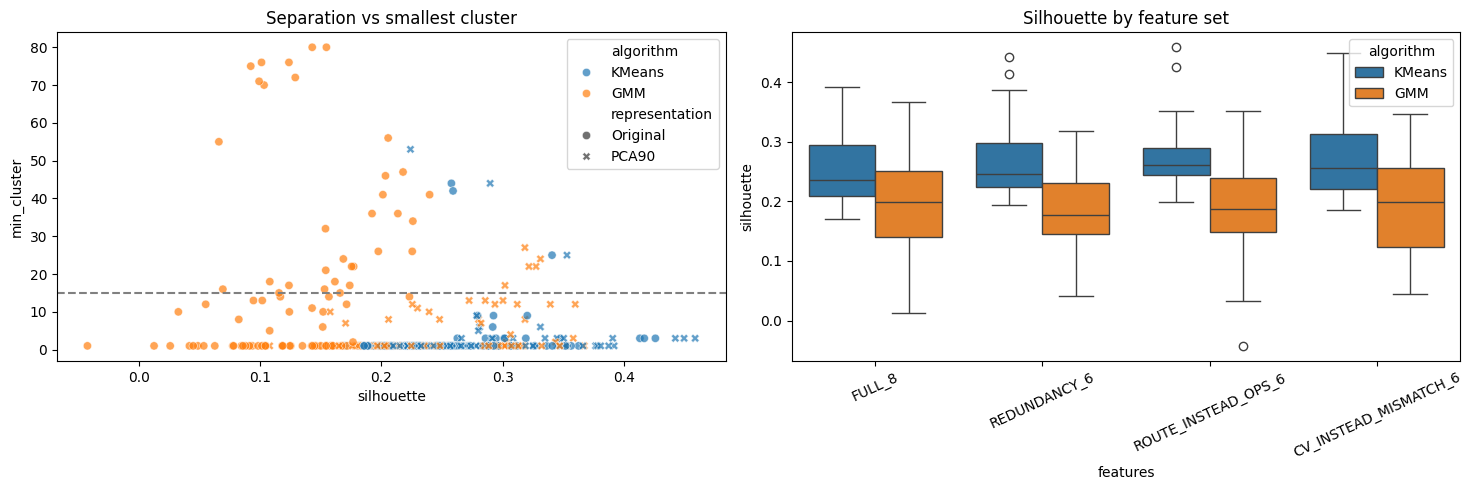

최소 군집 15개 이상인 상위 모델:


,model_id,features,scaler,log,representation,algorithm,k,pca_dimensions,silhouette,davies_bouldin,calinski_harabasz,min_cluster,max_cluster,cluster_sizes,n_clusters_found,min_cluster_5pct,eligible
12,FULL_8__Standard__log0__PCA90__KMeans__K3,FULL_8,Standard,False,PCA90,KMeans,3,5,0.353033,1.124706,100.307435,25,196,25/65/196,3,True,True
0,FULL_8__Standard__log0__Original__KMeans__K3,FULL_8,Standard,False,Original,KMeans,3,8,0.340720,1.164123,94.941335,25,197,25/64/197,3,True,True
18,FULL_8__Standard__log0__PCA90__GMM__K3,FULL_8,Standard,False,PCA90,GMM,3,5,0.331189,1.919675,55.456020,24,210,24/52/210,3,True,True
210,ROUTE_INSTEAD_OPS_6__Standard__log0__PCA90__GM...,ROUTE_INSTEAD_OPS_6,Standard,False,PCA90,GMM,3,5,0.327494,1.439437,60.023639,22,208,22/56/208,3,True,True
234,ROUTE_INSTEAD_OPS_6__Standard__log1__PCA90__GM...,ROUTE_INSTEAD_OPS_6,Standard,True,PCA90,GMM,3,4,0.321698,2.905802,39.963485,22,224,22/40/224,3,True,True
114,REDUNDANCY_6__Standard__log0__PCA90__GMM__K3,REDUNDANCY_6,Standard,False,PCA90,GMM,3,5,0.318335,1.532376,58.276882,27,200,27/59/200,3,True,True
306,CV_INSTEAD_MISMATCH_6__Standard__log0__PCA90__...,CV_INSTEAD_MISMATCH_6,Standard,False,PCA90,GMM,3,5,0.301916,1.844622,51.019547,17,211,17/58/211,3,True,True
228,ROUTE_INSTEAD_OPS_6__Standard__log1__PCA90__KM...,ROUTE_INSTEAD_OPS_6,Standard,True,PCA90,KMeans,3,4,0.289671,1.202410,112.654231,44,162,44/80/162,3,True,True
216,ROUTE_INSTEAD_OPS_6__Standard__log1__Original_...,ROUTE_INSTEAD_OPS_6,Standard,True,Original,KMeans,3,6,0.259065,1.326235,96.606158,42,160,42/84/160,3,True,True
24,FULL_8__Standard__log1__Original__KMeans__K3,FULL_8,Standard,True,Original,KMeans,3,8,0.257707,1.294415,102.930747,44,166,44/76/166,3,True,True


In [5]:
# 5% (=15개) 미만의 극소수 군집은 별도로 표시
results['min_cluster_5pct']=results['min_cluster']>=15
results['eligible']=results['min_cluster_5pct'] & (results['n_clusters_found']==results['k'])
rank=results.sort_values(['eligible','silhouette'],ascending=[False,False])
rank.to_csv(RESULT/'02_ranked_experiments.csv',index=False,encoding='utf-8-sig')
fig,axs=plt.subplots(1,2,figsize=(15,5))
sns.scatterplot(data=results,x='silhouette',y='min_cluster',hue='algorithm',style='representation',alpha=.7,ax=axs[0])
axs[0].axhline(15,color='gray',ls='--');axs[0].set_title('Separation vs smallest cluster')
sns.boxplot(data=results,x='features',y='silhouette',hue='algorithm',ax=axs[1]);axs[1].tick_params(axis='x',rotation=25)
axs[1].set_title('Silhouette by feature set')
plt.tight_layout();plt.savefig(RESULT/'03_model_comparison.png',dpi=170,bbox_inches='tight');plt.show()
print('최소 군집 15개 이상인 상위 모델:')
display(results[results.eligible].sort_values('silhouette',ascending=False).head(12))


## 5. PCA 산점도 및 차원 축소 영향
시각화용 PCA 2차원 좌표는 **StandardScaler 기반**, 모델 평가 공간과 구분됩니다. PCA 90% 축소 모델은 해당 축소공간에서 실루엣을 계산합니다.

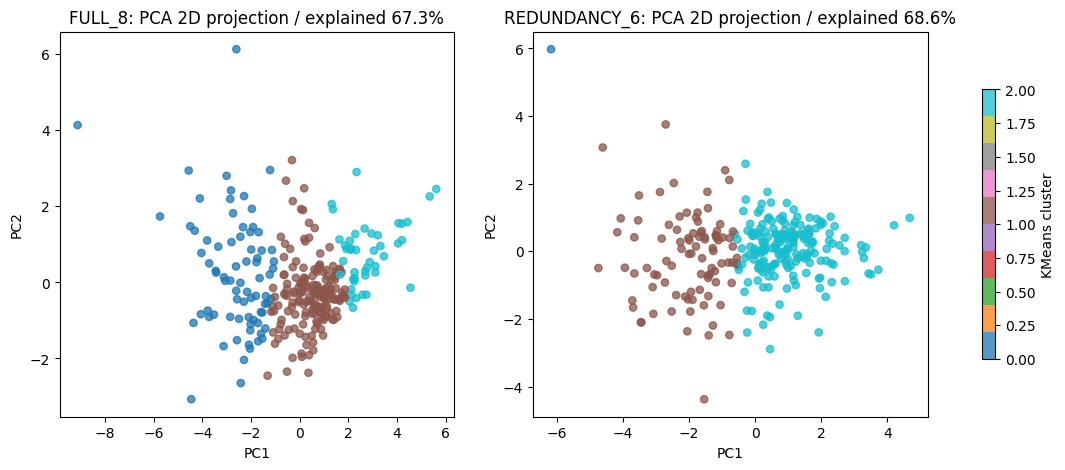

In [6]:
fig,axs=plt.subplots(1,2,figsize=(14,5))
for ax,fs in zip(axs,['FULL_8','REDUNDANCY_6']):
    X,_=prep(SETS[fs],'Standard',True,'Original')
    p=PCA(n_components=2,random_state=42)
    z=p.fit_transform(X)
    labels=fit_predict(X,'KMeans',3)
    sc=ax.scatter(z[:,0],z[:,1],c=labels,cmap='tab10',s=28,alpha=.75)
    ax.set_title(f'{fs}: PCA 2D projection / explained {p.explained_variance_ratio_.sum():.1%}')
    ax.set_xlabel('PC1');ax.set_ylabel('PC2')
fig.colorbar(sc,ax=axs.tolist(),shrink=.7,label='KMeans cluster')
plt.savefig(RESULT/'04_PCA_projection.png',dpi=170,bbox_inches='tight');plt.show()
summary=[]
for key,p in pca_cache.items():
    if p is not None:summary.append({'features':key[0],'scaler':key[1],'log':key[2],
        'pca_components':int(p.n_components_),'explained_variance':float(p.explained_variance_ratio_.sum())})
pd.DataFrame(summary).to_csv(RESULT/'05_PCA_variance.csv',index=False,encoding='utf-8-sig')


## 6. 후보 모델의 초기값 안정성 및 80% 재표본 안정성

- 초기값 안정성: 동일한 286개 정류장에 대해 seed 변경 후 ARI 비교.
- 재표본 안정성: 무작위 80% 정류장만으로 재학습한 결과를 원래 모델의 동일 부분집합과 ARI 비교.
- **주의:** 재표본의 결과를 단순히 동일 ID의 군집으로 간주하지 않으며 ARI로 라벨 교환을 허용. 이는 월별 재현성 검증과는 별개.

In [7]:
top=results[results.eligible].sort_values('silhouette',ascending=False).head(4)
# KMeans, GMM 최소 한 모델씩 포함하고, 기준 A/B 모델도 안정성 검토
baseline=results[(results.features=='REDUNDANCY_6')&(results.scaler=='Standard')&(~results.log)&(results.representation=='Original')&(results.algorithm=='KMeans')&(results.k==3)]
selected=pd.concat([top,baseline]).drop_duplicates('model_id')
if not any(selected.algorithm=='GMM'):
    gmm=results[(results.algorithm=='GMM') & results.eligible].sort_values('silhouette',ascending=False).head(1)
    selected=pd.concat([selected,gmm]).drop_duplicates('model_id')
rng=np.random.default_rng(20261012)
stability=[]
for _,r in selected.iterrows():
    key=(r['features'],r['scaler'],bool(r['log']),r['representation'])
    X=Xs_cache[key]; ref=labels_cache[r['model_id']]
    seeds=[11,19,31,57,83,101,131,173]
    seed_ari=[adjusted_rand_score(ref,fit_predict(X,r['algorithm'],int(r['k']),seed=s)) for s in seeds]
    sample_ari=[]
    for i in range(10):
        ix=np.sort(rng.choice(len(X),size=int(len(X)*.8),replace=False))
        alt=fit_predict(X[ix],r['algorithm'],int(r['k']),seed=500+i)
        sample_ari.append(adjusted_rand_score(ref[ix],alt))
    stability.append({'model_id':r.model_id,'seed_ari_mean':np.mean(seed_ari),'seed_ari_min':np.min(seed_ari),
      'subsample_ari_mean':np.mean(sample_ari),'subsample_ari_min':np.min(sample_ari),
      'silhouette':r.silhouette,'min_cluster':r.min_cluster})
stab=pd.DataFrame(stability).sort_values('subsample_ari_mean',ascending=False)
stab.to_csv(RESULT/'06_stability_ARI.csv',index=False,encoding='utf-8-sig')
display(stab)


,model_id,seed_ari_mean,seed_ari_min,subsample_ari_mean,subsample_ari_min,silhouette,min_cluster
4,REDUNDANCY_6__Standard__log0__Original__KMeans...,0.959773,0.853610,0.862540,0.530074,0.292446,9
3,ROUTE_INSTEAD_OPS_6__Standard__log0__PCA90__GM...,0.976089,0.848215,0.857491,0.636221,0.327494,22
2,FULL_8__Standard__log0__PCA90__GMM__K3,0.986873,0.964994,0.826044,0.484465,0.331189,24
1,FULL_8__Standard__log0__Original__KMeans__K3,1.000000,1.000000,0.772757,0.475213,0.340720,25
0,FULL_8__Standard__log0__PCA90__KMeans__K3,0.981377,0.961943,0.756567,0.409569,0.353033,25


## 7. 후보 모델의 군집별 수요·공급 특성 및 정류장 목록

,model_id,cluster,count,avg_daily_passengers,avg_daily_operations,passengers_per_operation,temporal_mismatch,low_supply_hour_ratio_lt1avg,weekend_weekday_demand_ratio,unique_route_count
0,FULL_8__Standard__log0__PCA90__KMeans__K3,0,196,309.644444,420.361111,0.762031,0.179499,0.208333,0.640282,4.0
1,FULL_8__Standard__log0__PCA90__KMeans__K3,1,65,50.977778,129.333333,0.325734,0.322223,0.208333,0.443575,1.0
2,FULL_8__Standard__log0__PCA90__KMeans__K3,2,25,2011.844444,1164.455556,1.851488,0.158230,0.166667,0.649786,13.0
3,FULL_8__Standard__log0__Original__KMeans__K3,0,64,50.666667,131.161111,0.314795,0.323275,0.208333,0.438169,1.0
4,FULL_8__Standard__log0__Original__KMeans__K3,1,197,309.633333,417.477778,0.762653,0.179854,0.208333,0.639813,4.0
5,FULL_8__Standard__log0__Original__KMeans__K3,2,25,2011.844444,1164.455556,1.851488,0.158230,0.166667,0.649786,13.0
6,FULL_8__Standard__log0__PCA90__GMM__K3,0,210,321.050000,435.950000,0.783309,0.178374,0.208333,0.642586,4.0
7,FULL_8__Standard__log0__PCA90__GMM__K3,1,24,764.338889,931.833333,0.925435,0.223825,0.166667,0.632031,9.5
8,FULL_8__Standard__log0__PCA90__GMM__K3,2,52,50.666667,116.066666,0.314795,0.331161,0.208333,0.411728,1.0
9,ROUTE_INSTEAD_OPS_6__Standard__log0__PCA90__GM...,0,56,50.666667,93.094444,0.314795,0.334924,0.250000,0.431429,1.0


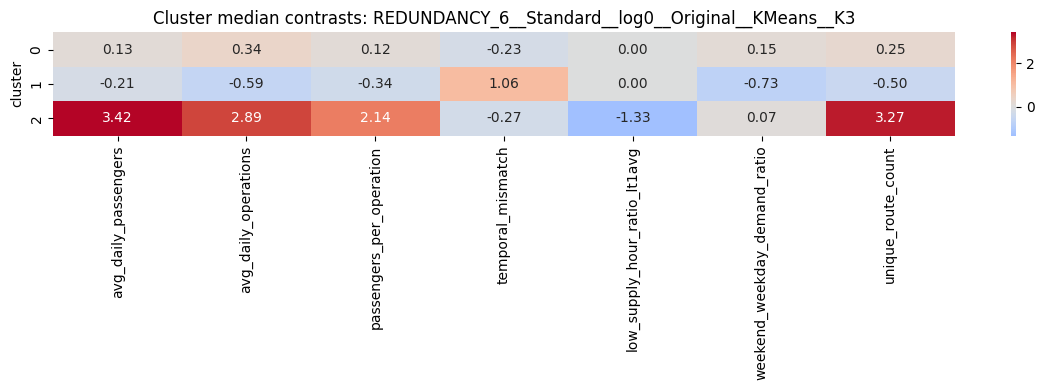

안정성 기준 선두 모델: REDUNDANCY_6__Standard__log0__Original__KMeans__K3
이 순위는 참고용이며 I-MOD 도입 우선순위가 아닙니다.


In [8]:
original=['avg_daily_passengers','avg_daily_operations','passengers_per_operation',
 'temporal_mismatch','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio','unique_route_count']
profiles=[]
for _,r in selected.iterrows():
    tmp=df[['station_name']+original].copy()
    tmp['cluster']=labels_cache[r.model_id];tmp['model_id']=r.model_id
    tmp[['model_id','station_name','cluster']].to_csv(RESULT/f'labels_{r.model_id}.csv',index=False,encoding='utf-8-sig')
    med=tmp.groupby('cluster')[original].median()
    med['count']=tmp.groupby('cluster').size()
    med['model_id']=r.model_id
    profiles.append(med.reset_index())
profile=pd.concat(profiles,ignore_index=True)
profile.to_csv(RESULT/'07_candidate_cluster_profiles_median.csv',index=False,encoding='utf-8-sig')
display(profile[['model_id','cluster','count']+original].head(24))
# 가장 안정적인 후보 모델: 최소 군집 기준 충족 + silhouette + stability 균형. 기계적 최종 채택은 하지 않음.
chosen=stab.iloc[0].model_id
r=results.loc[results.model_id==chosen].iloc[0]
selected_labels=labels_cache[chosen]
raw_profile=df[original].copy();raw_profile['cluster']=selected_labels
cluster_medians=raw_profile.groupby('cluster')[original].median()
# 변수별 중앙값의 군집 간 상대 수준 시각화: 해당 변수의 286개 표준편차 사용
hm=(cluster_medians-df[original].median())/df[original].std().replace(0,np.nan)
plt.figure(figsize=(12,4));sns.heatmap(hm,annot=True,fmt='.2f',cmap='coolwarm',center=0)
plt.title('Cluster median contrasts: '+chosen);plt.tight_layout()
plt.savefig(RESULT/'08_cluster_profiles_heatmap.png',dpi=180,bbox_inches='tight');plt.show()
print('안정성 기준 선두 모델:',chosen)
print('이 순위는 참고용이며 I-MOD 도입 우선순위가 아닙니다.')


## 8. 핵심 진단: 중복 변수, 스케일러, 로그, PCA, 알고리즘 효과

In [9]:
# 비교 조건별 결과 요약: 동일 K/동일 데이터가 아니라는 점을 유의
factors=[]
for factor in ['features','scaler','log','representation','algorithm']:
    t=results.groupby(factor).agg(experiments=('model_id','count'),
       median_silhouette=('silhouette','median'),top_silhouette=('silhouette','max'),
       median_min_cluster=('min_cluster','median')).reset_index()
    t.insert(0,'factor',factor);t=t.rename(columns={factor:'condition'})
    factors.append(t)
factors=pd.concat(factors,ignore_index=True)
factors.to_csv(RESULT/'09_factor_comparison.csv',index=False,encoding='utf-8-sig')
display(factors)
print('해석 원칙: 서로 다른 PCA 공간 실루엣 직접 비교에 주의. 비교는 동일 특성공간의 조건쌍과 안정성 함께 확인.')


,factor,condition,experiments,median_silhouette,top_silhouette,median_min_cluster
0,features,CV_INSTEAD_MISMATCH_6,96,0.228843,0.449664,1.0
1,features,FULL_8,96,0.225549,0.391968,1.0
2,features,REDUNDANCY_6,96,0.225940,0.442444,1.0
3,features,ROUTE_INSTEAD_OPS_6,96,0.239522,0.458776,1.0
4,scaler,Robust,192,0.231256,0.458776,1.0
5,scaler,Standard,192,0.226014,0.387427,1.0
6,log,False,192,0.247757,0.458776,1.0
7,log,True,192,0.217544,0.391968,1.0
8,representation,Original,192,0.197412,0.425979,1.0
9,representation,PCA90,192,0.253437,0.458776,1.0


해석 원칙: 서로 다른 PCA 공간 실루엣 직접 비교에 주의. 비교는 동일 특성공간의 조건쌍과 안정성 함께 확인.


## 9. 결과 압축 다운로드

In [10]:
zipname='Michuhol_IMOD_STEP2_5_Results.zip'
with zipfile.ZipFile(zipname,'w',zipfile.ZIP_DEFLATED) as z:
    for p in RESULT.glob('*'):
        z.write(p,arcname=p.name)
print('산출물 개수:',len(list(RESULT.glob('*'))),'\nZIP:',zipname)
try:
    from google.colab import files
    files.download(zipname)
except ImportError:
    print('로컬 실행 결과:',Path(zipname).resolve())


산출물 개수: 14 
ZIP: Michuhol_IMOD_STEP2_5_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>